# Baseline CNN
**Authors:** Kai Henrik Herbst & Bell Wassim

### 1. Data Loading and Preprocessing
Load the dataset and perform the necessary preprocessing.

In [1]:
# Import the data loading and preprocessing function from our utility script
# Note: Ensure the .py file is in the same directory
from data_prep import load_stl10_data

# Load the dataset. The function handles downloading, splitting (80/20), 
# resizing to 96x96, normalizing, and one-hot encoding the labels.
# I am setting the batch size to 128 for efficient GPU utilization.
ds_train, ds_val, ds_test = load_stl10_data()

2026-03-15 21:31:52.226305: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-03-15 21:31:52.226810: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-15 21:31:52.235321: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-03-15 21:31:52.399201: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-03-15 21:31:55.165802: W tensorflow/compiler/tf2tensorrt/utils/py_utils.cc:38] TF

2026-03-15 21:32:02.025856: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:02:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-03-15 21:32:02.026415: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


Dataset split: 4000 training, 1000 validation, 8000 testing.
Data preprocessing complete!


### 2. Network Creation (Baseline Model)
Here we define the architecture of our first, simple Convolutional Neural Network (Baseline). We use a stack of Conv2D and MaxPooling2D layers for feature extraction, followed by Dense layers for classification.

In [2]:
import keras
from keras import layers

# Input shape definition for our STL-10 images (96x96 pixels, 3 color channels)
inputs = keras.Input(shape=(96, 96, 3))

# Feature Learning Part of the CNN
x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(inputs)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
x = layers.MaxPooling2D(pool_size=2)(x)
x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)

# Classification Part
x = layers.Flatten()(x)

# Final output layer: 10 units for our 10 classes. 
outputs = layers.Dense(10, activation="softmax")(x)

# Instantiate the baseline model
model_baseline = keras.Model(inputs=inputs, outputs=outputs, name="Baseline_CNN")

# Display the architecture summary to verify the parameters
model_baseline.summary()

Model: "Baseline_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 96, 96, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 51200)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │       512,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 605,258 (2.31 MB)

 Trainable params: 605,258 (2.31 MB)

 Non-trainable params: 0 (0.00 B)

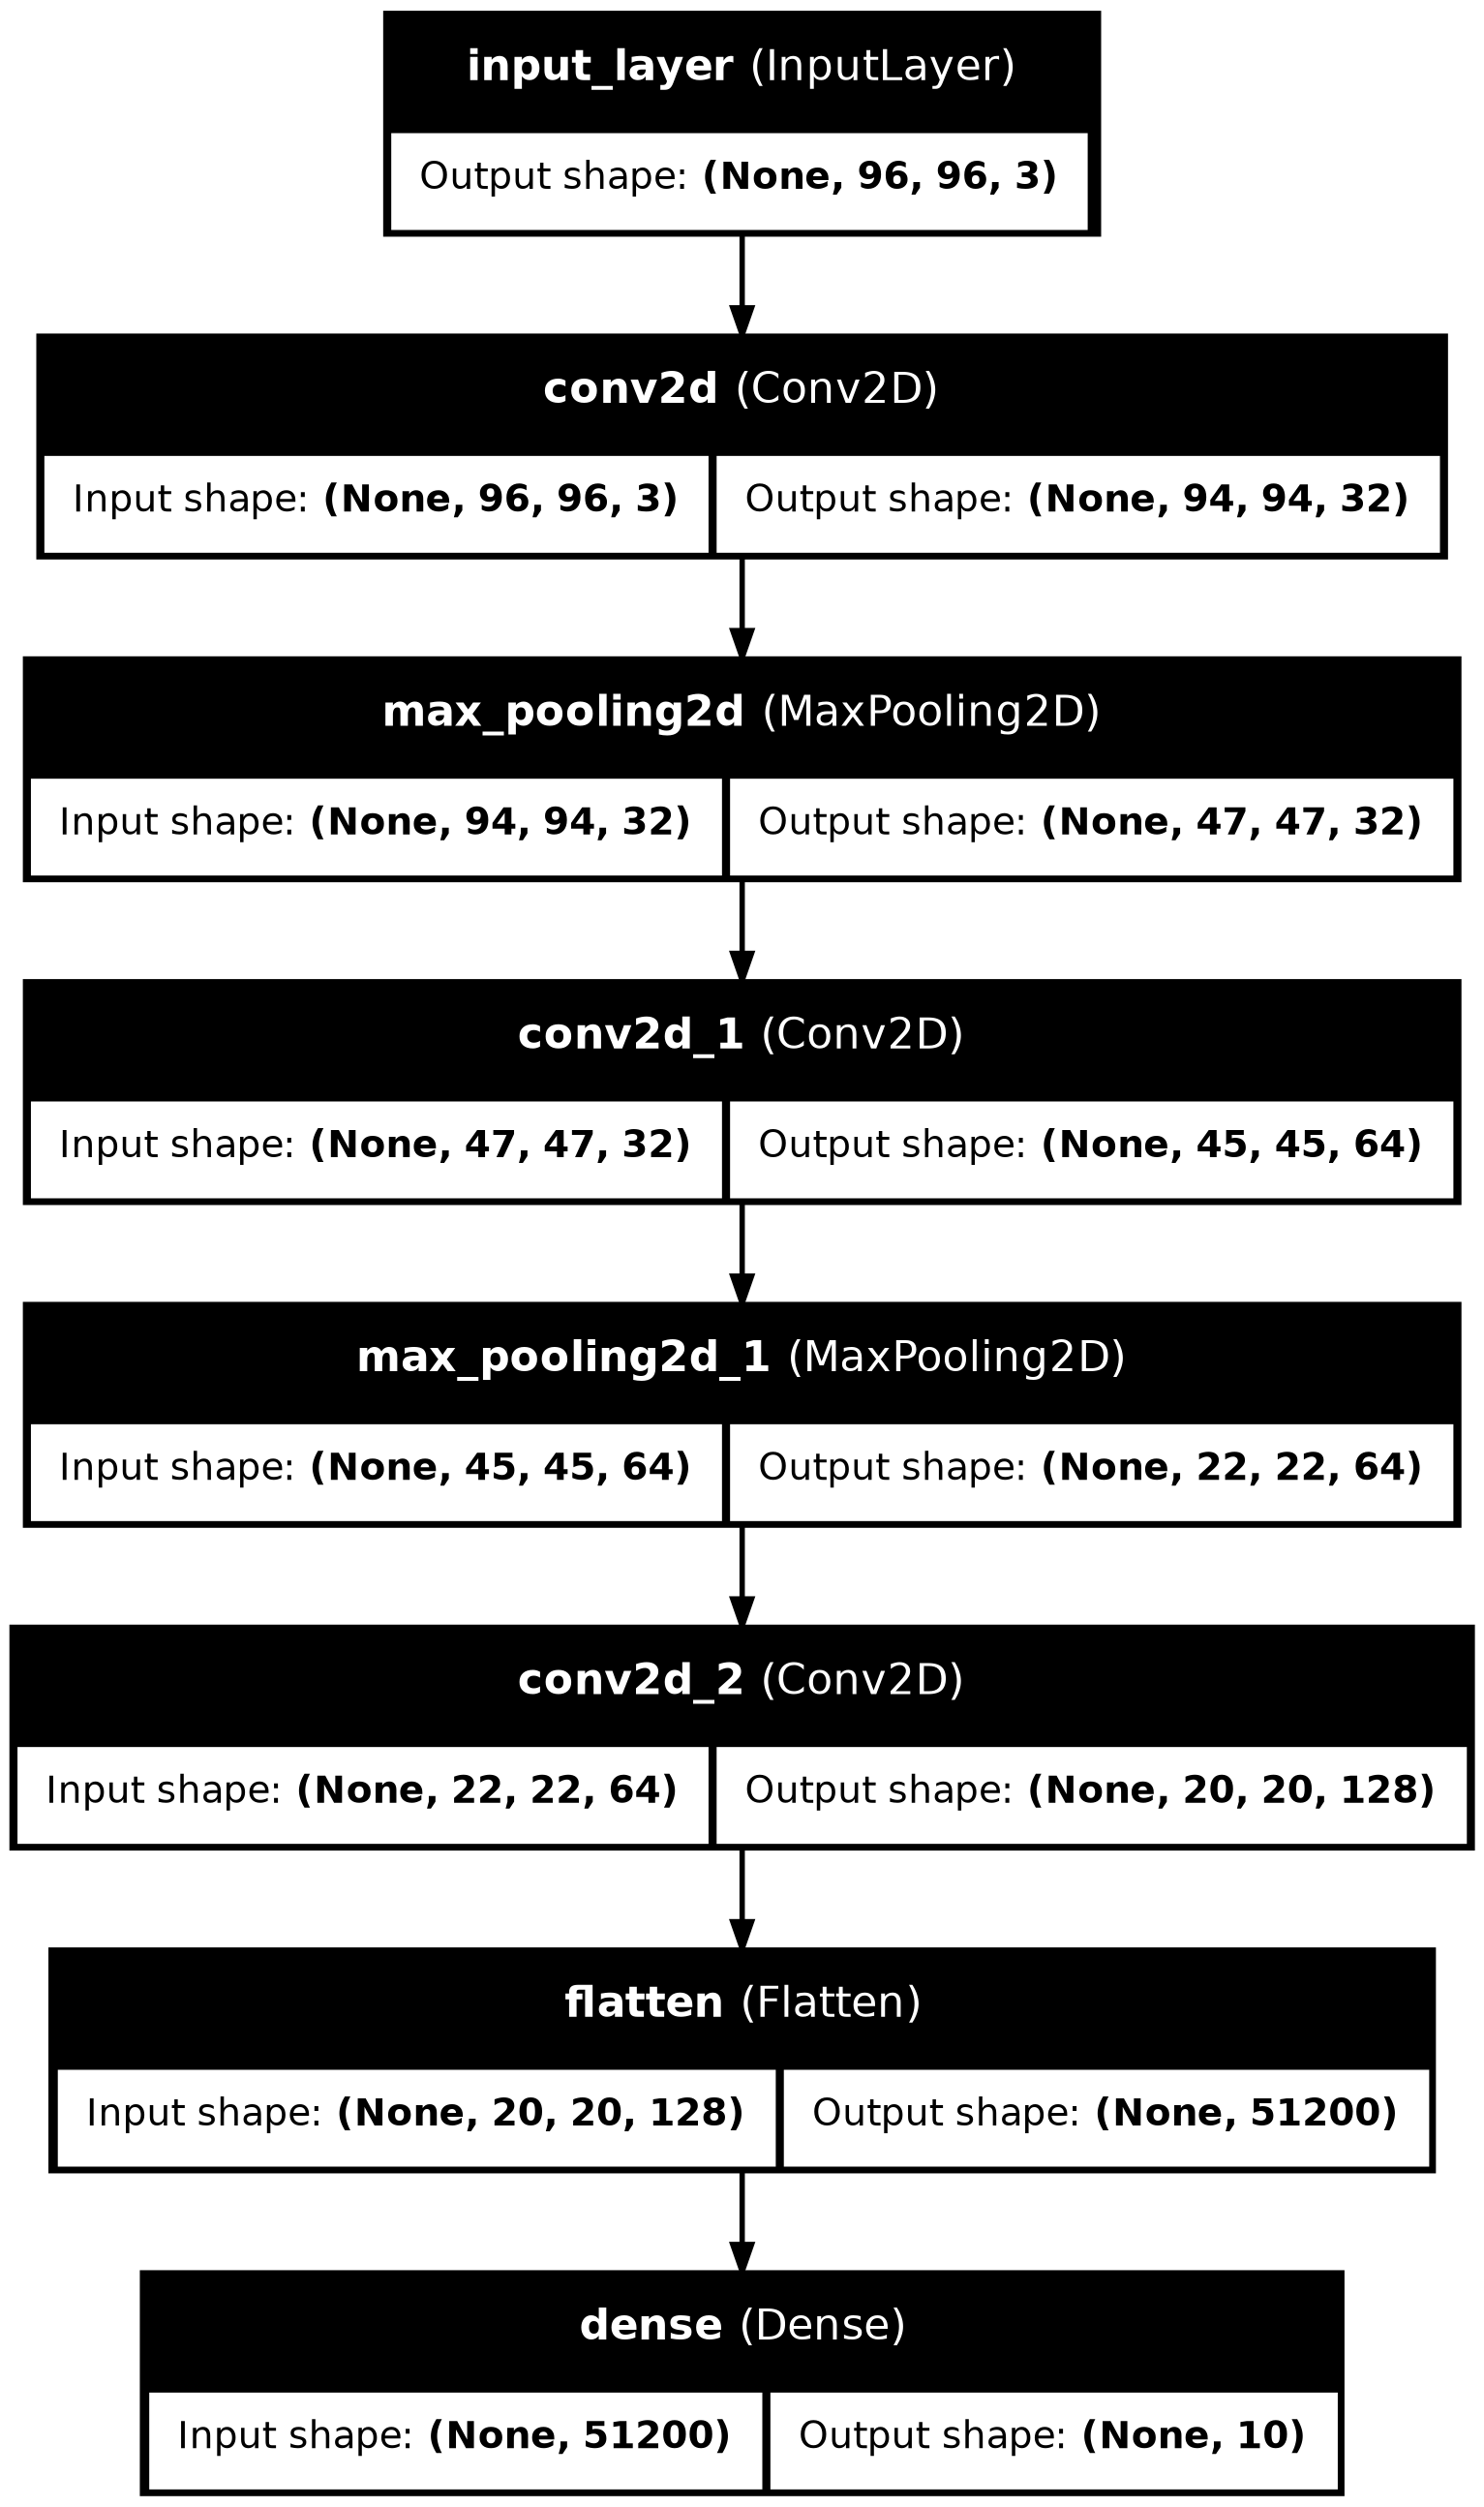

In [3]:
# 1. Graphical visualization of the architecture (Academic Flowchart)
from tensorflow import keras

keras.utils.plot_model(model_baseline, show_shapes=True, show_layer_names=True)

### 3. Model Training
We compile the model specifying the optimizer and loss function, and then train it on our preprocessed training data. The validation data is used to monitor the model's performance on unseen data and to check for overfitting.

In [4]:
# Compile the model: configuring the optimizer, loss function, and metrics
model_baseline.compile(
    optimizer='rmsprop',              # Starting with rmsprop, as seen in the lecture
    loss='categorical_crossentropy',  # Categorical crossentropy, required for one-hot encoded labels
    metrics=['accuracy']              # Track accuracy to evaluate our performance
)

# Start the training process
print("Starting the training process for our baseline model...")
history_baseline = model_baseline.fit(
    ds_train,
    epochs=5,                         # Starting with 5 epochs, as seen in the lecture
    validation_data=ds_val            # Evaluate on unseen data after each epoch.
                                      # NOTE: The model does NOT learn from ds_val. Backpropagation 
                                      # (weight updating) is disabled for this dataset. It is strictly 
                                      # used to monitor generalization and detect overfitting.
)

Starting the training process for our baseline model...
Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 19s 275ms/step - accuracy: 0.2325 - loss: 2.1090 - val_accuracy: 0.3290 - val_loss: 1.7717
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 16s 230ms/step - accuracy: 0.4108 - loss: 1.6320 - val_accuracy: 0.3780 - val_loss: 1.8270
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 15s 228ms/step - accuracy: 0.4893 - loss: 1.3990 - val_accuracy: 0.5900 - val_loss: 1.1525
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 256ms/step - accuracy: 0.5635 - loss: 1.2283 - val_accuracy: 0.6080 - val_loss: 1.0507
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 257ms/step - accuracy: 0.6177 - loss: 1.0545 - val_accuracy: 0.6580 - val_loss: 0.9089


We visualize the training and validation progress to monitor the model's learning behavior. These plots help identify if the model has converged, if the number of epochs was sufficient, and whether there are signs of overfitting or underfitting during the 5-epoch run.

In [5]:
import matplotlib.pyplot as plt

def plot(history):
    accuracy = history.history["accuracy"]
    val_accuracy = history.history["val_accuracy"]
    loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epochs = range(1, len(accuracy) + 1)

    plt.plot(epochs, accuracy, "b-o", label="Training accuracy")
    plt.plot(epochs, val_accuracy, "r--o", label="Validation accuracy")
    plt.title("Training and validation accuracy")
    plt.legend()
    plt.figure()

    plt.plot(epochs, loss, "b-o", label="Training loss")
    plt.plot(epochs, val_loss, "r-o", label="Validation loss")
    plt.title("Training and validation loss")
    plt.legend()
    plt.show()

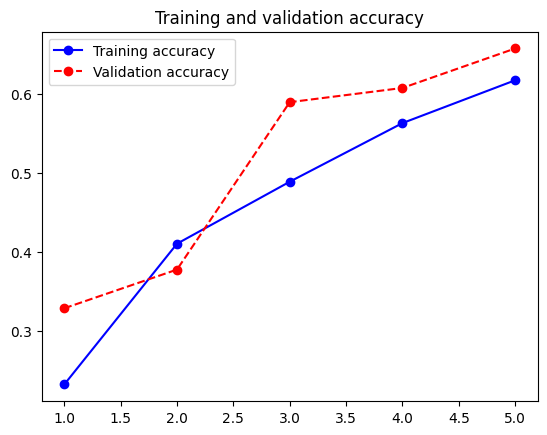

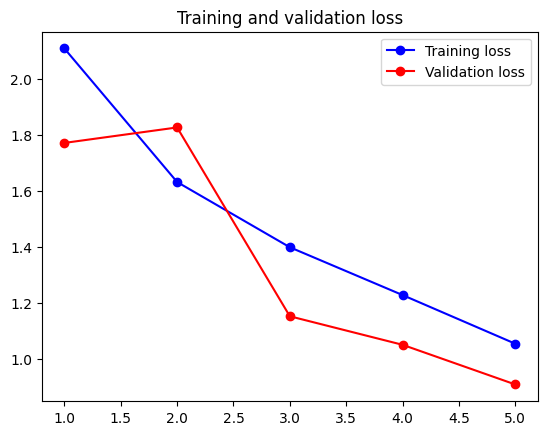

In [7]:
plot(history_baseline)

### 4. Evaluation
To determine the generalization capability of our baseline model, we evaluate it using the test dataset (`ds_test`). Since these images were neither used for training nor for validation, the results provide an unbiased estimate of the model's performance in a real-world scenario.

In [8]:
# Evaluate the trained baseline model on the unseen test dataset
print("Evaluating the model on the test dataset...")
test_loss, test_accuracy = model_baseline.evaluate(ds_test)

print(f"\nFinal Test Loss: {test_loss:.3f}")
print(f"Final Test Accuracy: {test_accuracy * 100:.3f}%")

Evaluating the model on the test dataset...
125/125 ━━━━━━━━━━━━━━━━━━━━ 12s 104ms/step - accuracy: 0.4979 - loss: 1.4540

Final Test Loss: 1.454
Final Test Accuracy: 49.788%
